# 03 — SOP Incident Analysis

**Goal:** apply the project's deterministic incident engine and inspect its outputs.

Prerequisite: `src/incident_engine.py` must exist. Run this notebook from the project root. Temperature rules are scenario assumptions because the dataset does not identify cargo type; the SOP temperature limits apply to fresh perishables.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.incident_engine import load_shipments, get_incident_report

shipments = load_shipments()
report = get_incident_report(shipments)

print("Shipment records:", len(shipments))
print("Incident events:", len(report))
print("Unique records with incidents:", report["record_id"].nunique() if not report.empty else 0)

Shipment records: 32065
Incident events: 72118
Unique records with incidents: 31769


## 1. Incident category breakdown

,events
type,
Temperature Below Range,21817
Port Congestion,19566
Tier 2 Escalation,15440
Critical Temperature Breach,8674
Spoilage Risk,6621


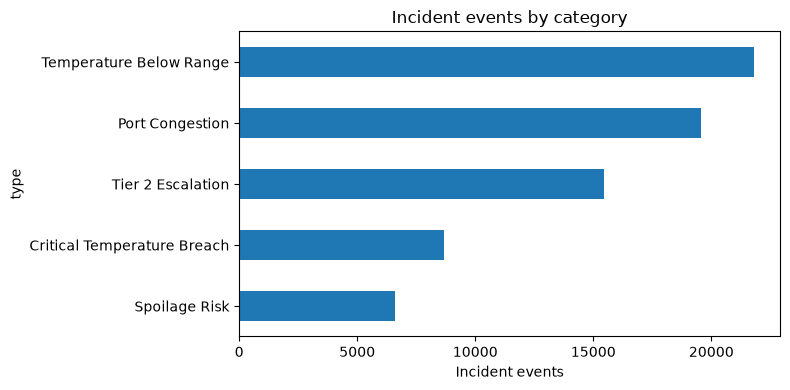

In [2]:
if report.empty:
    print("No incidents detected.")
else:
    counts = report["type"].value_counts()
    display(counts.rename("events").to_frame())
    ax = counts.sort_values().plot(kind="barh", figsize=(8, 4), title="Incident events by category")
    ax.set_xlabel("Incident events")
    plt.tight_layout()
    plt.show()

## 2. Severity breakdown

In [3]:
if not report.empty:
    display(pd.crosstab(report["type"], report["severity"], margins=True))
    display(report.groupby("severity").agg(
        incident_events=("record_id", "size"),
        unique_records=("record_id", "nunique")
    ).sort_values("incident_events", ascending=False))

severity,Critical,High,All
type,,,
Critical Temperature Breach,8674,0,8674
Port Congestion,0,19566,19566
Spoilage Risk,6621,0,6621
Temperature Below Range,0,21817,21817
Tier 2 Escalation,0,15440,15440
All,15295,56823,72118


,incident_events,unique_records
severity,,
High,56823,30024
Critical,15295,8674


## 3. Latest incident events

In [4]:
if not report.empty:
    display(report.sort_values("timestamp", ascending=False).head(15))

,record_id,timestamp,latitude,longitude,temperature,eta_delay,type,severity,action
72117,32064,2024-08-29 00:00:00,38.576482,-94.579542,18.796515,4.068440,Tier 2 Escalation,High,Escalate to Tier 2 Logistics Manager.
72116,32064,2024-08-29 00:00:00,38.576482,-94.579542,18.796515,4.068440,Port Congestion,High,Recommend diversion to Inland Empire Overflow ...
72115,32064,2024-08-29 00:00:00,38.576482,-94.579542,18.796515,4.068440,Spoilage Risk,Critical,Divert to the nearest emergency cold-storage f...
72114,32064,2024-08-29 00:00:00,38.576482,-94.579542,18.796515,4.068440,Critical Temperature Breach,Critical,Contact driver and restart auxiliary cooling.
72113,32063,2024-08-28 23:00:00,32.082410,-70.070154,-6.951137,4.759411,Port Congestion,High,Recommend diversion to Inland Empire Overflow ...
72112,32063,2024-08-28 23:00:00,32.082410,-70.070154,-6.951137,4.759411,Temperature Below Range,High,Inspect refrigeration settings and cargo condi...
72111,32062,2024-08-28 22:00:00,42.963338,-82.149873,29.410878,0.485288,Critical Temperature Breach,Critical,Contact driver and restart auxiliary cooling.
72110,32061,2024-08-28 21:00:00,34.670137,-89.893091,-2.517654,2.700635,Tier 2 Escalation,High,Escalate to Tier 2 Logistics Manager.
72109,32061,2024-08-28 21:00:00,34.670137,-89.893091,-2.517654,2.700635,Temperature Below Range,High,Inspect refrigeration settings and cargo condi...
72108,32060,2024-08-28 20:00:00,48.496665,-104.031158,-8.835069,4.394370,Tier 2 Escalation,High,Escalate to Tier 2 Logistics Manager.


## 4. Records with the most incident flags

In [5]:
if not report.empty:
    per_record = (report.groupby("record_id")
                  .agg(incident_count=("type", "size"),
                       incident_types=("type", lambda x: ", ".join(sorted(set(x)))))
                  .sort_values("incident_count", ascending=False))
    display(per_record.head(15))

,incident_count,incident_types
record_id,,
13,4,"Critical Temperature Breach, Port Congestion, ..."
32064,4,"Critical Temperature Breach, Port Congestion, ..."
15,4,"Critical Temperature Breach, Port Congestion, ..."
26224,4,"Critical Temperature Breach, Port Congestion, ..."
26203,4,"Critical Temperature Breach, Port Congestion, ..."
26210,4,"Critical Temperature Breach, Port Congestion, ..."
26201,4,"Critical Temperature Breach, Port Congestion, ..."
26153,4,"Critical Temperature Breach, Port Congestion, ..."
26106,4,"Critical Temperature Breach, Port Congestion, ..."


## Important interpretation notes

- Incident events are not the same as unique affected shipments/records. One record can trigger multiple rules.
- The source SOP's temperature thresholds are specifically for fresh perishables. The dataset has no cargo-type field, so temperature flags must be presented as an assumption, not confirmed SOP violations.
- The SOP specifies a response for temperatures above 4°C, but does not prescribe a specific mitigation for below-zero readings.
- The congestion diversion rule is scoped to the Port of Long Beach / LA in the SOP. The dataset has no port-identity field, so applying it to every row is a scenario assumption.
- This is a rule-based alert simulation, not proof that a real dispatcher action occurred.